# 02 · Window features, calibration, feature table  *(owner: Rithwika)*

Turns the per-frame signals in `features/` into one row per time window: PERCLOS, blink statistics, yawn statistics, head-pose and eyebrow statistics. Per-subject calibration normalises each person's signals first.

Outputs (in `data/`): `windows.csv`, `feature_groups.json` (used for the ablation), `subject_folds.csv`, `run_info.json`, and `signals/` (calibrated per-frame signals for the LSTM in notebook 05).

**Things to decide and report**
- Window length / step (`WIN_S`, `STEP_S`) - ablate 10 / 30 / 60 s.
- Calibration mode: `none` (one baseline for everyone), `subject_all` (statistics of all of that subject's videos pooled), `subject_alert` (that subject's alert video only, like "calibrate at the start of a drive") or `per_video` (each video normalised by its own statistics). `subject_all` uses the test subject's other-class videos, so it can be optimistic; compare modes and state which you used.
- Thresholds (blink, PERCLOS, yawn) - set them by looking at the histograms below, not by guessing.

*Note: windows overlap by 50%, so neighbouring windows are correlated. That is fine as long as train/test splits are done by subject or by video (notebooks 03/04 do this).*

In [1]:
import os, glob, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

FEATURE_DIR = "features"
OUT_DIR = "data"
os.makedirs(OUT_DIR, exist_ok=True)

# ---------------- windows ----------------
WIN_S, STEP_S = 30.0, 15.0
MIN_VALID_FRAC = 0.8          # drop windows where the face is missing for more than 20% of frames
MAX_GAP_S = 0.5               # interpolate face-lost gaps up to this length

# ---------------- calibration ----------------
CALIBRATION = "subject_alert"   # "none" | "subject_all" | "subject_alert" | "per_video"

# ---------------- event thresholds (on calibrated signals) ----------------
# NOTE: with MediaPipe EAR at ~15 fps the eye rarely drops below 50% of its open value (a blink lasts only 1-3 frames),
# so thresholds must be fairly high. Check the histogram below before changing them.
SMOOTH_FRAMES = 1             # 1 = no smoothing. (A 3-frame median would erase 1-2 frame blinks at 15 fps.)
BLINK_THR = 0.80              # blink = EAR below 80% of the subject's open-eye EAR ...
MIN_BLINK_S, LONG_BLINK_S = 0.06, 0.50   # ... for at least ~1 frame (0.067 s at 15 fps); >= 0.5 s = "long" blink
CLOSED_THRS = (0.5, 0.7, 0.8, 0.9)       # PERCLOS variants: fraction of time EAR < 50/70/80/90% of open
RUN_THR = 0.8                 # longest continuous run below this level -> closed_run_max_s
YAWN_THR, MIN_YAWN_S = 0.30, 1.0   # mouth opening above subject's resting MAR by this much, for >= 1 s

OFFICIAL_FOLDS_DIR = None     # e.g. r"C:/RLDD": use the dataset authors' 5 folds (Fold1..Fold5 folder names) instead of random folds
REQUIRE_ALL_CLASSES = True    # drop subjects that do not have windows for alert, low AND drowsy
LABEL2Y = {"alert": 0, "low": 1, "drowsy": 2}

# ---------------- head-pose helpers ----------------
# Raw Euler angles can jump by ~180 deg between frames (solver branch flips, sideways videos with roll ~ +-90).
# So angles are treated as CIRCULAR quantities and summarised with robust statistics.
HEAD_JUMP_CAP = 30.0          # deg/frame: larger frame-to-frame jumps are ignored as pose-flip artefacts
def wrap180(x):
    return (np.asarray(x, dtype=float) + 180.0) % 360.0 - 180.0
def circ_median(x):
    r = np.radians(np.asarray(x, dtype=float)); r = r[~np.isnan(r)]
    return float(np.degrees(np.arctan2(np.median(np.sin(r)), np.median(np.cos(r)))))

In [2]:
def load_video(path):
    d = np.load(path)
    X = pd.DataFrame(d["X"], columns=list(d["cols"]))
    t = d["t"].astype(float)
    subject, label, *part = os.path.basename(path)[:-4].split("_")   # 32_drowsy_p1 -> part "p1"
    part = part[0] if part else "p0"
    fps = 1.0 / np.median(np.diff(t))                       # effective fps after striding
    s = pd.DataFrame({
        "ear":  X[["ear_l", "ear_r"]].mean(axis=1, skipna=True),
        "mar":  X["mar"],
        "pitch": X["pitch"], "yaw": X["yaw"], "roll": X["roll"],
        "brow": X[["brow_l", "brow_r"]].mean(axis=1, skipna=True),
    })
    s = s.interpolate(limit=max(1, int(MAX_GAP_S * fps)), limit_area="inside")
    if SMOOTH_FRAMES > 1:
        s["ear"] = s["ear"].rolling(SMOOTH_FRAMES, center=True, min_periods=1).median()
    return dict(subject=subject, label=label, part=part, t=t, fps=fps, df=s)


paths = sorted(glob.glob(os.path.join(FEATURE_DIR, "*.npz")))
videos = [load_video(p) for p in paths]
print(f"{len(videos)} videos | {len({v['subject'] for v in videos})} subjects | "
      f"effective fps ~ {np.median([v['fps'] for v in videos]):.1f}")

182 videos | 60 subjects | effective fps ~ 15.0


In [3]:
# ---------------- calibration baselines ----------------
def baseline_from(frames):
    return dict(ear_open=np.nanpercentile(frames.ear, 90),   # robust "eyes open" level
                mar_med=np.nanmedian(frames.mar), brow_med=np.nanmedian(frames.brow),
                pitch_med=circ_median(frames.pitch.values), yaw_med=circ_median(frames.yaw.values),
                roll_med=circ_median(frames.roll.values))

subjects = sorted({v["subject"] for v in videos})
global_base = baseline_from(pd.concat([v["df"] for v in videos]))
baselines = {}
for s in subjects:
    if CALIBRATION == "none":
        baselines[s] = global_base                           # one shared baseline for everyone
    elif CALIBRATION == "subject_all":
        baselines[s] = baseline_from(pd.concat([v["df"] for v in videos if v["subject"] == s]))
    elif CALIBRATION == "subject_alert":
        alert = [v["df"] for v in videos if v["subject"] == s and v["label"] == "alert"]
        baselines[s] = baseline_from(pd.concat(alert)) if alert else global_base
    elif CALIBRATION == "per_video":                         # (table below shows subject-level values; each video really uses its own)
        baselines[s] = baseline_from(pd.concat([v["df"] for v in videos if v["subject"] == s]))
    else:
        raise ValueError(CALIBRATION)

def base_for(v):
    """Baseline used to normalise one video."""
    if CALIBRATION == "per_video":
        return baseline_from(v["df"])                        # each video normalised by its OWN unlabeled statistics
    return baselines[v["subject"]]

def normalise(df, b):
    return pd.DataFrame({
        "ear_n": df.ear / b["ear_open"], "mar_c": df.mar - b["mar_med"], "brow_n": df.brow / b["brow_med"],
        "pitch_c": wrap180(df.pitch - b["pitch_med"]), "yaw_c": wrap180(df.yaw - b["yaw_med"]),
        "roll_c": wrap180(df.roll - b["roll_med"])})

pd.DataFrame(baselines).T.round(3).head()

,ear_open,mar_med,brow_med,pitch_med,yaw_med,roll_med
01,0.308,0.022,0.260,5.407,-29.029,-92.639
02,0.279,0.054,0.226,7.061,-7.074,-2.639
03,0.288,0.016,0.234,1.811,-2.331,-88.987
04,0.253,0.016,0.256,-18.836,-10.637,2.544
05,0.312,0.033,0.261,-6.657,25.271,-92.487


### Look at the signals before trusting any threshold
The left histogram should show a main peak near 1.0 (eyes open) and a shoulder/tail below it (blinks and closures); put `BLINK_THR` at the foot of that shoulder, not inside the main peak. Yawns should be a tail on the right (`YAWN_THR`).

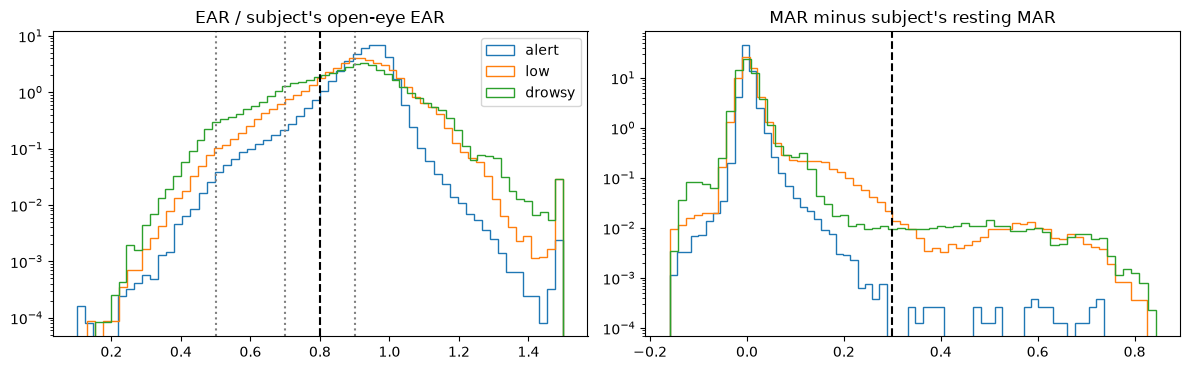

In [4]:
norm = {(v["subject"], v["label"], v["part"]): normalise(v["df"], base_for(v)) for v in videos}
pooled = {lab: pd.concat([n for (s, l, p), n in norm.items() if l == lab]) for lab in LABEL2Y}

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for lab, d in pooled.items():
    ax[0].hist(d.ear_n.dropna().clip(0, 1.5), bins=60, histtype="step", density=True, label=lab)
    ax[1].hist(d.mar_c.dropna().clip(-0.2, 1.0), bins=60, histtype="step", density=True, label=lab)
for thr in CLOSED_THRS: ax[0].axvline(thr, ls=":", c="gray")
ax[0].axvline(BLINK_THR, ls="--", c="k")
ax[1].axvline(YAWN_THR, ls="--", c="k")
ax[0].set_title("EAR / subject's open-eye EAR"); ax[1].set_title("MAR minus subject's resting MAR")
ax[0].legend(); ax[0].set_yscale("log"); ax[1].set_yscale("log"); plt.tight_layout(); plt.show()

### Head-pose sanity check
Lists the videos where the head angles are most often far (> 60 deg) from the subject's typical pose. Large values mean flipped/unstable pose estimates (or a head turned far away); those windows are handled robustly below, but note the worst ones.

In [5]:
rows = []
for v in videos:
    d = norm[(v["subject"], v["label"], v["part"])]
    rows.append(dict(subject=v["subject"], label=v["label"], part=v["part"],
                     **{a: float((d[f"{a}_c"].abs() > 60).mean()) for a in ("pitch", "yaw", "roll")}))
flip = pd.DataFrame(rows); flip["worst"] = flip[["pitch", "yaw", "roll"]].max(axis=1)
print(f"{(flip.worst > 0.05).sum()} of {len(flip)} videos have > 5% of frames with an angle > 60 deg from the subject's median")
display(flip.sort_values("worst", ascending=False).head(10).round(3))

27 of 182 videos have > 5% of frames with an angle > 60 deg from the subject's median


,subject,label,part,pitch,yaw,roll,worst
40,14,drowsy,p0,0.000,0.000,1.000,1.000
5,02,low,p0,0.000,0.000,1.000,1.000
7,03,drowsy,p0,0.000,0.000,1.000,1.000
8,03,low,p0,0.000,0.000,1.000,1.000
88,30,drowsy,p0,0.000,0.000,1.000,1.000
20,07,low,p0,0.000,0.000,1.000,1.000
4,02,drowsy,p0,0.002,0.000,1.000,1.000
76,26,drowsy,p0,0.000,0.004,0.999,0.999
41,14,low,p0,0.002,0.000,0.998,0.998
1,01,drowsy,p0,0.001,0.000,0.998,0.998


In [6]:
# ---------------- window features ----------------
def runs(mask):
    m = np.asarray(mask, bool).astype(np.int8)
    d = np.diff(np.concatenate(([0], m, [0])))
    return np.where(d == 1)[0], np.where(d == -1)[0]          # [start, end) index pairs

def window_features(w, fps):
    f = {}
    ear = w.ear_n.values; ev = ear[~np.isnan(ear)]
    # --- eye ---
    f["ear_mean"], f["ear_std"], f["ear_p10"] = ev.mean(), ev.std(), np.percentile(ev, 10)
    for thr in CLOSED_THRS:
        f[f"perclos_{int(thr * 100)}"] = float((ev < thr).mean())
    st, en = runs(np.nan_to_num(ear, nan=1.0) < BLINK_THR)
    dur = (en - st) / fps
    keep = dur >= MIN_BLINK_S
    st, en, dur = st[keep], en[keep], dur[keep]
    f["n_blinks"] = len(dur)
    f["blink_rate"] = len(dur) / (len(ear) / fps / 60.0)       # blinks per minute
    f["blink_dur_mean"] = dur.mean() if len(dur) else 0.0
    f["blink_dur_max"] = dur.max() if len(dur) else 0.0
    f["n_long_blinks"] = int((dur >= LONG_BLINK_S).sum())
    f["blink_depth_mean"] = float(np.mean([np.nanmin(ear[a:b]) for a, b in zip(st, en)])) if len(dur) else 1.0
    s2, e2 = runs(np.nan_to_num(ear, nan=1.0) < RUN_THR)
    f["closed_run_max_s"] = ((e2 - s2).max() / fps) if len(s2) else 0.0
    # --- mouth ---
    mar = w.mar_c.values; mv = mar[~np.isnan(mar)]
    f["mar_mean"], f["mar_std"], f["mar_max"] = mv.mean(), mv.std(), mv.max()
    f["mouth_open_frac"] = float((mv > YAWN_THR).mean())
    ys, ye = runs(np.nan_to_num(mar, nan=0.0) > YAWN_THR)
    f["n_yawns"] = int((((ye - ys) / fps) >= MIN_YAWN_S).sum())
    # --- head pose (robust: median / IQR-based spread / capped frame-to-frame motion) ---
    for a in ("pitch", "yaw", "roll"):
        v = w[f"{a}_c"].dropna().values
        q25, q75 = np.percentile(v, [25, 75])
        f[f"{a}_mean"], f[f"{a}_std"] = float(np.median(v)), float((q75 - q25) / 1.349)
    f["pitch_p10"] = np.nanpercentile(w.pitch_c.values, 10)    # head dropping forward/down
    step = np.abs(wrap180(np.diff(w[["pitch_c", "yaw_c", "roll_c"]].values, axis=0)))
    step = np.where(step > HEAD_JUMP_CAP, np.nan, step)       # ignore pose-flip jumps
    f["head_motion"] = float(np.nanmean(step) * fps) if np.isfinite(step).any() else 0.0   # deg/s
    # --- eyebrow ---
    bv = w.brow_n.dropna().values
    f["brow_mean"], f["brow_std"] = bv.mean(), bv.std()
    return f

GROUPS = {
    "eye":   ["ear_mean", "ear_std", "ear_p10"] + [f"perclos_{int(t * 100)}" for t in CLOSED_THRS] + ["n_blinks", "blink_rate",
              "blink_dur_mean", "blink_dur_max", "n_long_blinks", "blink_depth_mean", "closed_run_max_s"],
    "mouth": ["mar_mean", "mar_std", "mar_max", "mouth_open_frac", "n_yawns"],
    "head":  ["pitch_mean", "pitch_std", "yaw_mean", "yaw_std", "roll_std", "pitch_p10", "head_motion"],   # roll_mean is left out on purpose: it mostly encodes how the phone was rotated in that video
    "brow":  ["brow_mean", "brow_std"],
}

In [7]:
rows = []
for v in videos:
    nd = norm[(v["subject"], v["label"], v["part"])]
    t, fps = v["t"], v["fps"]
    start = 0.0
    while start + WIN_S <= t[-1] + 1e-6:
        m = (t >= start) & (t < start + WIN_S)
        w = nd[m]
        if m.sum() >= 0.5 * WIN_S * fps and w.ear_n.notna().mean() >= MIN_VALID_FRAC:
            rows.append(dict(subject=v["subject"], label=v["label"], part=v["part"], y=LABEL2Y[v["label"]],
                             video=f'{v["subject"]}_{v["label"]}', t_start=start, **window_features(w, fps)))
        start += STEP_S

W = pd.DataFrame(rows)
if REQUIRE_ALL_CLASSES:
    n_cls = W.groupby("subject").label.nunique()
    dropped = n_cls[n_cls < 3].index.tolist()
    print("Dropping subjects without windows in all 3 classes (report these!):", dropped)
    W = W[~W.subject.isin(dropped)].reset_index(drop=True)
W.to_csv(f"{OUT_DIR}/windows.csv", index=False)
json.dump(dict(calibration=CALIBRATION, win_s=WIN_S, step_s=STEP_S, blink_thr=BLINK_THR, closed_thrs=list(CLOSED_THRS)),
          open(f"{OUT_DIR}/run_info.json", "w"), indent=1)   # notebook 04 uses this to name its results folder
json.dump(GROUPS, open(f"{OUT_DIR}/feature_groups.json", "w"), indent=1)

# subject -> fold (5 folds of 12 subjects). Random by default; the dataset's official folds if OFFICIAL_FOLDS_DIR is set.
subs = np.array(sorted(W.subject.unique()))
folds = None
if OFFICIAL_FOLDS_DIR:
    import re
    fold_of = {}
    for pth in glob.glob(os.path.join(OFFICIAL_FOLDS_DIR, "**", "*.*"), recursive=True):
        m = re.search(r"Fold(\d)", pth)
        if m and os.path.splitext(pth)[1].lower() in (".mov", ".mp4", ".m4v"):
            fold_of[os.path.basename(os.path.dirname(pth))] = int(m.group(1)) - 1
    folds = pd.DataFrame({"subject": subs}); folds["fold"] = folds.subject.map(fold_of)
    if folds.fold.isna().any():
        print("WARNING: no official fold found for", folds[folds.fold.isna()].subject.tolist(), "- using random folds instead")
        folds = None
    else:
        folds["fold"] = folds.fold.astype(int); print("official folds used:", folds.fold.value_counts().sort_index().to_dict())
if folds is None:
    rng = np.random.default_rng(0); sh = subs.copy(); rng.shuffle(sh)
    folds = pd.DataFrame({"subject": sh, "fold": np.arange(len(sh)) % 5})
folds.to_csv(f"{OUT_DIR}/subject_folds.csv", index=False)

print(f"{len(W)} windows from {W.video.nunique()} videos, {W.subject.nunique()} subjects")
print(W.groupby("label").size().to_string())
print("NaNs in features:", int(W[sum(GROUPS.values(), [])].isna().sum().sum()))

Dropping subjects without windows in all 3 classes (report these!): []
7223 windows from 180 videos, 60 subjects
label
alert     2381
drowsy    2438
low       2404
NaNs in features: 0


In [8]:
# Calibrated per-frame signals, saved for the sequence model (notebook 05). Same calibration as the window features above.
SIG_COLS = ["ear_n", "mar_c", "brow_n", "pitch_c", "yaw_c"]       # roll is left out on purpose (it mostly encodes phone orientation)
os.makedirs(f"{OUT_DIR}/signals", exist_ok=True)
for v in videos:
    nd = norm[(v["subject"], v["label"], v["part"])]
    np.savez_compressed(f'{OUT_DIR}/signals/{v["subject"]}_{v["label"]}_{v["part"]}.npz', t=v["t"].astype(np.float32),
                        X=nd[SIG_COLS].values.astype(np.float32), fps=v["fps"], cols=np.array(SIG_COLS))
print(len(videos), "signal files saved to", f"{OUT_DIR}/signals")

182 signal files saved to data/signals


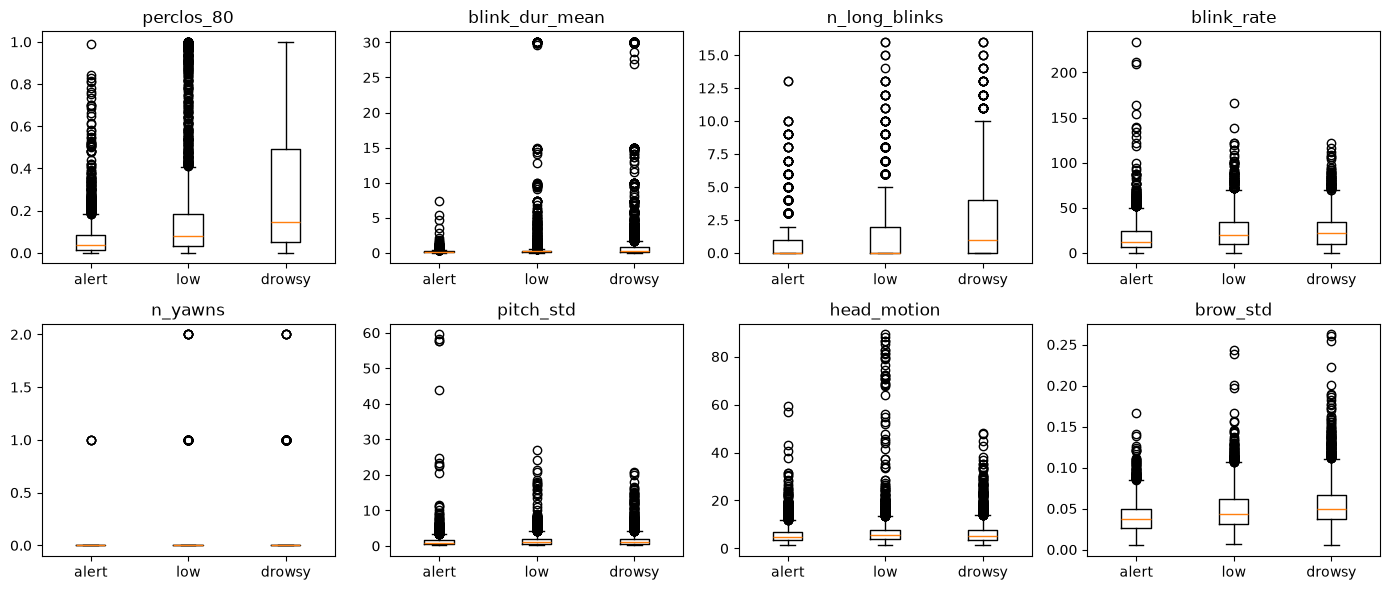

In [9]:
# Do the features separate the classes? (A quick look, not a result.)
show = ["perclos_80", "blink_dur_mean", "n_long_blinks", "blink_rate", "n_yawns", "pitch_std", "head_motion", "brow_std"]
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for a, c in zip(axes.ravel(), show):
    data = [W[W.label == l][c] for l in LABEL2Y]
    a.boxplot(data); a.set_xticks([1, 2, 3], list(LABEL2Y)); a.set_title(c)
plt.tight_layout(); plt.show()

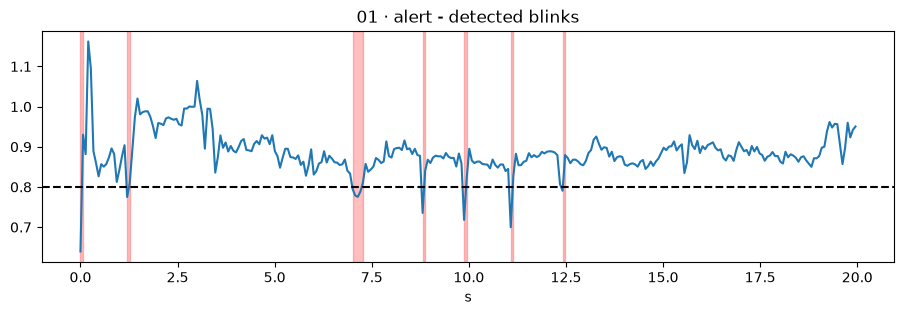

In [10]:
# Blink detection on a real segment: red = detected blink
v = videos[0]
nd = norm[(v["subject"], v["label"], v["part"])]
m = v["t"] < 20
ear = nd.ear_n.values[m]; t = v["t"][m]
st, en = runs(np.nan_to_num(ear, nan=1.0) < BLINK_THR)
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(t, ear); ax.axhline(BLINK_THR, ls="--", c="k")
for a, b in zip(st, en):
    if (b - a) / v["fps"] >= MIN_BLINK_S: ax.axvspan(t[a], t[min(b, len(t) - 1)], color="r", alpha=.25)
ax.set_title(f'{v["subject"]} · {v["label"]} - detected blinks'); ax.set_xlabel("s"); plt.show()

## Hand-off
`data/windows.csv`, `data/feature_groups.json` and `data/subject_folds.csv` are the inputs to notebook **03** (Archee). Report in the write-up: window length, calibration mode, all thresholds, and how many windows were dropped for missing faces.